## Library Setup for KNN-Based Recommendation

This section imports the required libraries for building a nearest-neighbors based recommendation system.

---

### Libraries Used

- Data handling and manipulation for structured datasets  
- Numerical computation for efficient array operations  
- Parsing utilities for handling structured string data  
- Text processing for normalization and cleaning  

---

### Machine Learning Components

- Feature scaling to normalize input data  
- Multi-label encoding for transforming genre data into numerical form  
- Nearest Neighbors algorithm for finding similar songs  

---

### Purpose

- Prepares the environment for implementing a KNN-based recommendation model  
- Enables efficient similarity search using distance-based methods  
- Supports feature engineering and preprocessing steps required for modeling  

In [2]:
import pandas as pd
import numpy as np
import ast
import re

from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.neighbors import NearestNeighbors

## Data Preparation for KNN Model

This section prepares the dataset for use in the nearest neighbors recommendation model.

---

### Data Loading

- Loads the final dataset containing songs and cleaned genre information  
- Serves as the input for feature extraction and similarity modeling  

---

### Artist Formatting

- Ensures that the artist field is consistently represented as a list  
- Converts string representations into structured lists when necessary  
- Handles parsing errors gracefully  

---

### Text Normalization

- Creates a cleaned version of track names  
- Removes extra whitespace and standardizes casing  
- Enables consistent matching during recommendation queries  

---

### Purpose

- Ensures uniform data structure across the dataset  
- Prepares clean and consistent inputs for similarity-based models  
- Reduces errors caused by inconsistent formatting  

In [3]:
df = pd.read_csv("songs_with_genres_final.csv")

def ensure_list(x):
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return [x]
    return x

df['artists'] = df['artists'].apply(ensure_list)
df['name_clean'] = df['name'].str.strip().str.lower()

## Genre Feature Encoding

This section transforms genre information into numerical features for use in the KNN-based recommendation model.

---

### Genre List Creation

- Converts genre strings into lists of individual genre labels  
- Removes empty values and trims whitespace  
- Ensures each track has a structured representation of its genres  

---

### Multi-Label Binarization

- Applies a multi-label encoding technique to convert genres into binary features  
- Each unique genre becomes a separate feature column  
- Indicates the presence or absence of each genre per track  

---

### Feature Weighting

- Scales genre features by a constant factor  
- Adjusts their relative importance in similarity calculations  

---

### Data Integration

- Combines the generated genre feature matrix with the original dataset  
- Ensures all features are consolidated into a single structure  

---

### Output Insight

- Displays the total number of genre-based features created  
- Provides an overview of the dimensionality added by genre encoding  

---

### Purpose

- Converts categorical genre data into a machine-readable format  
- Enables distance-based similarity computation in KNN  
- Enhances the representation of songs using genre information  

In [4]:
df['genre_list'] = df['genres_filtered'].fillna('').apply(
    lambda x: [g.strip() for g in x.split(',') if g]
)

mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(df['genre_list'])

genre_df = pd.DataFrame(genre_matrix, columns=mlb.classes_) * 0.5

df = pd.concat([df, genre_df], axis=1)

print("Genre features:", len(genre_df.columns))

Genre features: 597


In [5]:
base_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'popularity'
]

features = base_features + list(genre_df.columns)

df[features] = df[features].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features]).astype('float32')

print("Feature matrix shape:", X_scaled.shape)
X_scaled

Feature matrix shape: (173613, 607)


array([[-1.4752027 , -1.026358  , -1.5287219 , ..., -0.01046187,
        -0.00239999, -0.00480003],
       [ 1.5883622 , -0.5407496 , -0.1864772 , ..., -0.01046187,
        -0.00239999, -0.00480003],
       [-1.1972125 , -1.1944532 , -0.6088766 , ..., -0.01046187,
        -0.00239999, -0.00480003],
       ...,
       [ 0.5388076 ,  1.3904778 ,  1.6046436 , ..., -0.01046187,
        -0.00239999, -0.00480003],
       [ 0.7487185 ,  0.51264715,  0.7393297 , ..., -0.01046187,
        -0.00239999, -0.00480003],
       [ 1.7982731 ,  0.87872124,  1.1308689 , ..., -0.01046187,
        -0.00239999, -0.00480003]], shape=(173613, 607), dtype=float32)

## Feature Construction and Scaling

This section builds the final feature matrix used for similarity search in the KNN model.

---

### Feature Composition

- Combines:
  - Audio-based features such as danceability, energy, and tempo  
  - Genre-based features generated from multi-label encoding  

---

### Handling Missing Values

- Replaces missing values with zero  
- Ensures a complete and consistent feature set  

---

### Feature Scaling

- Applies standardization to normalize all features  
- Transforms data to have zero mean and unit variance  
- Prevents features with larger magnitudes from dominating distance calculations  

---

### Feature Matrix

- Generates a numerical matrix representing each track  
- Converts data into a format optimized for efficient computation  

---

### Output Insight

- Displays the shape of the feature matrix  
- Indicates the number of tracks and total features used  

---

### Purpose

- Creates a balanced representation of songs  
- Combines audio characteristics and genre information  
- Prepares data for KNN-based similarity search  

In [6]:
knn = NearestNeighbors(
    n_neighbors=20,        
    metric='euclidean',
    algorithm='brute'
)

knn.fit(X_scaled)

print("KNN model ready")

KNN model ready


## KNN-Based Recommendation Function

This section implements a recommendation system using the K-Nearest Neighbors (KNN) approach.

---

### Input Handling

- Accepts a song name and an optional artist name  
- Normalizes the input for consistent matching  
- Filters the dataset to locate the correct song  
- If multiple matches exist, selects the most popular one  

---

### Nearest Neighbor Search

- Uses the precomputed feature matrix to represent songs numerically  
- Finds the closest songs using a distance-based approach  
- Retrieves a pool of nearest neighbors for further filtering  

---

### Deduplication

- Removes duplicate entries based on song name and artist  
- Ensures unique recommendations  

---

### Artist Diversity Control

- Limits the number of recommendations per artist  
- Prevents overrepresentation of a single artist  
- Maintains diversity in the recommendation list  

---

### Result Selection

- Iterates through nearest neighbors in order of similarity  
- Selects the top results based on the requested number  

---

### Output

- Returns structured recommendations including:
  - Song name  
  - Artists  
  - Genres  
  - Popularity  

---

### Purpose

- Provides a fast and scalable recommendation method  
- Uses distance-based similarity for efficient retrieval  
- Ensures balanced and diverse recommendations  

In [7]:
from collections import defaultdict

def normalize_name(x):
    x = x.lower()
    x = re.sub(r'[^\w\s]', '', x)
    return x.strip()

def get_main_artist(lst):
    return lst[0] if isinstance(lst, list) and lst else None

def recommend_knn(song_name, artist_name=None, n=5):

    song_name_clean = song_name.strip().lower()

    matches = df[df['name_clean'] == song_name_clean]

    if artist_name:
        matches = matches[matches['artists'].apply(
            lambda x: artist_name.lower() in [a.lower() for a in x]
        )]

    if matches.empty:
        print("Song not found")
        return []

    idx = matches.sort_values(by='popularity', ascending=False).index[0]

    distances, indices = knn.kneighbors(
        X_scaled[idx].reshape(1, -1),
        n_neighbors=30
    )

    indices = indices.flatten()

    seen_tracks = set()
    artist_count = defaultdict(int)
    results = []

    for i in indices:
        if i == idx:
            continue

        name = normalize_name(df.loc[i, 'name'])
        artist = get_main_artist(df.loc[i, 'artists'])

        if artist is None:
            continue

        key = (name, artist)

        # remove duplicates
        if key in seen_tracks:
            continue

        # max 2 per artist
        if artist_count[artist] >= 2:
            continue

        seen_tracks.add(key)
        artist_count[artist] += 1

        results.append({
            "name": df.loc[i, 'name'],
            "artists": df.loc[i, 'artists'],
            "genres": df.loc[i, 'genres_filtered'],
            "popularity": df.loc[i, 'popularity']
        })

        if len(results) >= n:
            break

    return results

In [8]:
recs = recommend_knn("DNA.", "Kendrick Lamar", 4)

for i, song in enumerate(recs, 1):
    print(f"Recommendation {i}")
    print(f"Name       : {song['name']}")
    print(f"Artists    : {', '.join(song['artists'])}")
    print(f"Genres     : {song['genres']}")
    print(f"Popularity : {song['popularity']}")
    print("-" * 50)

Recommendation 1
Name       : Alright
Artists    : Kendrick Lamar
Genres     : conscious hip hop, hip hop, jazz hip hop, neo soul, political hip hop, west coast hip hop
Popularity : 73
--------------------------------------------------
Recommendation 2
Name       : Institutionalized
Artists    : Kendrick Lamar, Bilal, Anna Wise, Snoop Dogg
Genres     : conscious hip hop, hip hop, jazz hip hop, neo soul, political hip hop, west coast hip hop
Popularity : 60
--------------------------------------------------
Recommendation 3
Name       : TEMPTATION
Artists    : Joey Bada$$
Genres     : banned, conscious hip hop, east coast hip hop, hip hop, neo soul, political hip hop, pop rap
Popularity : 68
--------------------------------------------------
Recommendation 4
Name       : Cold as Ice
Artists    : M.O.P.
Genres     : hardcore hip hop, hip hop
Popularity : 54
--------------------------------------------------


### GRAPHS AND ANALYSIS  
Here we have analyzed our recommnedations by comparing them against the input song like a line plot, radar comparison, heatmap etc.

In [9]:
def get_song_index(song_name, artist_name=None):

    song_name_clean = song_name.strip().lower()

    matches = df[df['name_clean'] == song_name_clean]

    if artist_name:
        matches = matches[matches['artists'].apply(
            lambda x: artist_name.lower() in [a.lower() for a in x]
        )]

    if matches.empty:
        print("Song not found")
        return None

    # pick most popular if multiple
    idx = matches.sort_values(by='popularity', ascending=False).index[0]
    return idx

In [10]:
from collections import defaultdict

def normalize_name(x):
    return x.lower().strip()

def get_main_artist(lst):
    return lst[0] if isinstance(lst, list) and lst else None


def recommend_knn_idx(idx, k=5):

    distances, indices = knn.kneighbors(
        X_scaled[idx].reshape(1, -1),
        n_neighbors=30   # larger pool
    )

    indices = indices.flatten()

    seen_tracks = set()
    artist_count = defaultdict(int)
    results = []

    for i in indices:

        if i == idx:
            continue

        name = normalize_name(df.loc[i, 'name'])
        artist = get_main_artist(df.loc[i, 'artists'])

        if artist is None:
            continue

        key = (name, artist)

        # ❌ remove duplicates
        if key in seen_tracks:
            continue

        # ❌ limit same artist
        if artist_count[artist] >= 2:
            continue

        seen_tracks.add(key)
        artist_count[artist] += 1
        results.append(i)

        if len(results) >= k:
            break

    return results

In [11]:
def recommend_knn_by_name(song_name, artist_name=None, k=5):

    idx = get_song_index(song_name, artist_name)
    if idx is None:
        return None, []

    recs = recommend_knn_idx(idx, k)
    return idx, recs

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
def compare_features_scaled(input_idx, rec_indices):

    feature_names = base_features
    feature_indices = list(range(len(base_features))) 

    plt.figure(figsize=(10, 5))

    # Input song
    input_vals = X_scaled[input_idx, feature_indices]
    plt.plot(feature_names, input_vals, marker='o', linewidth=2, label='Input')

    # Recommendations
    for i, idx in enumerate(rec_indices):
        rec_vals = X_scaled[idx, feature_indices]
        plt.plot(feature_names, rec_vals, marker='o', alpha=0.7, label=f'Rec {i+1}')

    plt.xticks(rotation=45)
    plt.title("Scaled Audio Feature Comparison")
    plt.legend()
    plt.show()

In [14]:
def heatmap_compare_scaled(input_idx, rec_indices):

    indices = [input_idx] + list(rec_indices)
    labels = ["Input"] + [f"Rec {i+1}" for i in range(len(rec_indices))]

    feature_indices = list(range(len(base_features)))
    data = X_scaled[indices][:, feature_indices]

    plt.figure(figsize=(8, 4))
    sns.heatmap(
        data,
        yticklabels=labels,
        xticklabels=base_features,
        cmap="coolwarm"
    )

    plt.title("Scaled Feature Heatmap")
    plt.show()

In [15]:
def radar_compare_scaled(input_idx, rec_indices):

    features_to_plot = base_features[:6]  # keep readable
    feature_indices = [base_features.index(f) for f in features_to_plot]

    angles = np.linspace(0, 2*np.pi, len(features_to_plot), endpoint=False).tolist()
    angles += angles[:1]

    plt.figure(figsize=(6,6))

    # Input
    input_vals = X_scaled[input_idx, feature_indices].tolist()
    input_vals += input_vals[:1]

    plt.plot(angles, input_vals, linewidth=2, label="Input")
    plt.fill(angles, input_vals, alpha=0.25)

    # Recommendations
    for i, idx in enumerate(rec_indices):
        vals = X_scaled[idx, feature_indices].tolist()
        vals += vals[:1]

        plt.plot(angles, vals, linewidth=1.5, alpha=0.8, label=f"Rec {i+1}")
        plt.fill(angles, vals, alpha=0.1)

    plt.xticks(angles[:-1], features_to_plot)
    plt.title("Scaled Radar Comparison")
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    plt.show()

### Genre comparison and Jaccard similarity  
In this we have taken the input song and compared the common genres with our recommended songs to analyse the affect of genres in our engine  
We have used a Jaccard Score which divides the No. of common genres by No. of total unique genres between the both of them

In [16]:
def compare_genres(input_idx, rec_indices):

    input_name = df.loc[input_idx, 'name']
    input_artist = ", ".join(df.loc[input_idx, 'artists'])
    input_genres = set(df.loc[input_idx, 'genre_list'])

    print("INPUT SONG")
    print(f"Name   : {input_name}")
    print(f"Artist : {input_artist}")
    print(f"Genres : {', '.join(input_genres)}")
    print("-" * 50)

    for i, idx in enumerate(rec_indices):

        rec_name = df.loc[idx, 'name']
        rec_artist = ", ".join(df.loc[idx, 'artists'])
        rec_genres = set(df.loc[idx, 'genre_list'])

        overlap = input_genres & rec_genres
        union = input_genres | rec_genres

        similarity = len(overlap) / len(union) if union else 0

        print(f"\nRecommendation {i+1}")
        print(f"Name       : {rec_name}")
        print(f"Artists    : {rec_artist}")
        print(f"Genres     : {', '.join(rec_genres)}")
        print(f"Common     : {', '.join(overlap) if overlap else 'None'}")
        print(f"Jaccard    : {round(similarity, 3)}")
        print("-" * 50)

### SHORTCOMING OF KNN AS COMAPARED TO COSINE SIMILARITY  
## Here we can see the model is only recommending 4 songs instead of 5 in the case of cosine similarity  
This is because after applying the filters (no more than 2 songs from the artist, etc.) there are not enough songs present in the cluster pool to be recommended to the user thus making the knn model less flexible than cosine similarity despite being otherwise similar in performance.

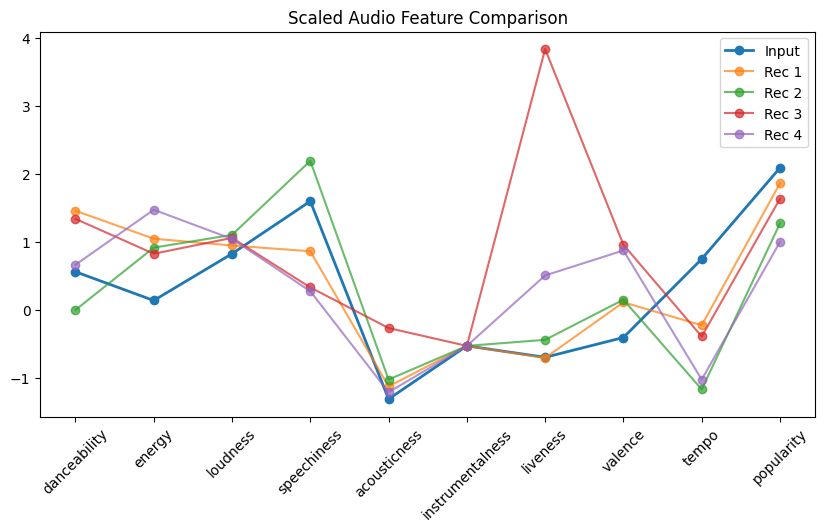

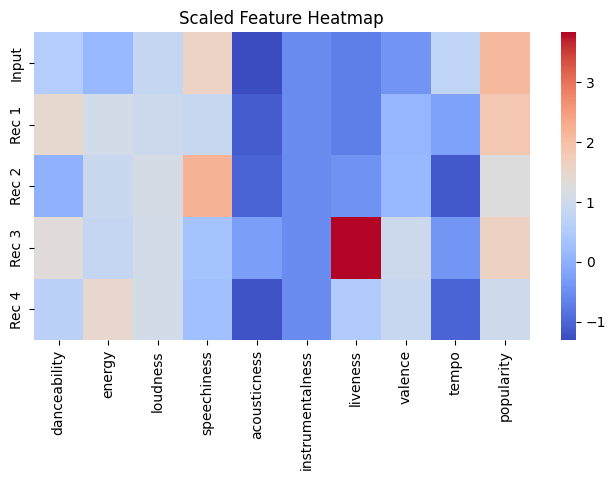

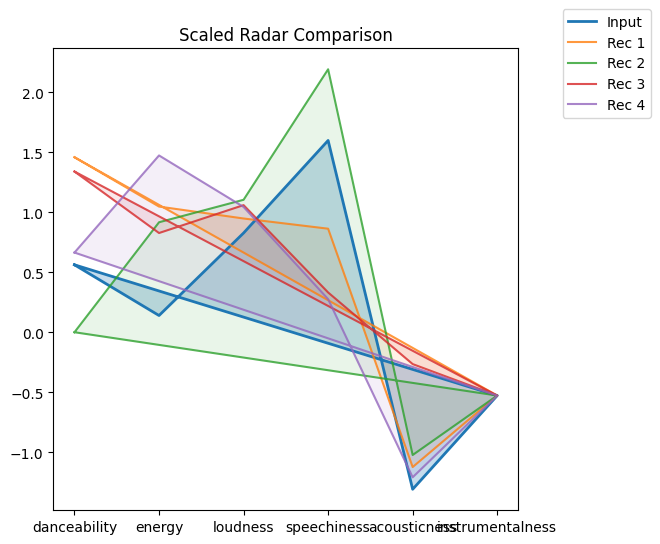

INPUT SONG
Name   : DNA.
Artist : Kendrick Lamar
Genres : hip hop, conscious hip hop, trap, hardcore hip hop, west coast hip hop, political hip hop
--------------------------------------------------

Recommendation 1
Name       : Alright
Artists    : Kendrick Lamar
Genres     : hip hop, conscious hip hop, neo soul, jazz hip hop, west coast hip hop, political hip hop
Common     : west coast hip hop, hip hop, political hip hop, conscious hip hop
Jaccard    : 0.5
--------------------------------------------------

Recommendation 2
Name       : Institutionalized
Artists    : Kendrick Lamar, Bilal, Anna Wise, Snoop Dogg
Genres     : hip hop, conscious hip hop, neo soul, jazz hip hop, west coast hip hop, political hip hop
Common     : west coast hip hop, hip hop, political hip hop, conscious hip hop
Jaccard    : 0.5
--------------------------------------------------

Recommendation 3
Name       : TEMPTATION
Artists    : Joey Bada$$
Genres     : pop rap, hip hop, conscious hip hop, neo soul, 

In [18]:
idx, recs_knn = recommend_knn_by_name("DNA.", "Kendrick Lamar", 5)

compare_features_scaled(idx, recs_knn)
heatmap_compare_scaled(idx, recs_knn)
radar_compare_scaled(idx, recs_knn)
compare_genres(idx, recs_knn)